# Exercise 3: Sequence-to-Sequence Models for Transliteration (Arabic

---

to English)

## Introduction

In this exercise, we will explore different sequence-to-sequence (seq2seq) models. The goal is to implement various encoder-decoder architectures for the task of **transliteration of Arabic words to English**. Transliteration is the process of converting text from one script to another, and in this case, we aim to convert Arabic script into Latin script using sequence-to-sequence models. This exercise covers different types of encoder-decoder models, including basic LSTM/GRU models, bidirectional encoders, and ultimately a bidirectional encoder-decoder model with attention (as an optional additional task). We will evaluate the performance of each model using **BLEU scores**.

### Key Notions:

- **Encoder-Decoder Architecture**: A neural network architecture that consists of two parts:
  - **Encoder**: Takes an input sequence (e.g., a word in Arabic script) and compresses it into a fixed-size context vector (or sequence of vectors).
  - **Decoder**: Takes the context vector and generates the output sequence (the transliterated word in English), one token at a time.

- **Bidirectional RNN**: A type of recurrent neural network (RNN) where two separate RNNs process the sequence in both forward and backward directions. This allows the model to capture both past and future context, improving performance on tasks like transliteration.

- **Attention Mechanism**: A mechanism that allows the decoder to focus on specific parts of the input sequence at each time step. It improves the model's ability to handle long sequences by enabling the decoder to dynamically select which part of the encoder's output should be used to generate the next token.

---

## Tasks

### Task 1: Dataset Analysis and Preprocessing

1. **Analyze the dataset**: Inspect the distribution of sequence lengths and choose appropriate maximum sequence lengths for both the input and output sequences.
   
2. **Choose vocabulary sizes**: Decide on the vocabulary sizes for both input (Arabic characters) and output (Latin characters). Consider using character-level tokenization or subword tokenization techniques like BPE (Byte Pair Encoding).
   
3. **Sequence Padding and Truncation**: Pad or truncate sequences to the chosen maximum length and prepare input-output pairs for training.

---

### Task 2: Basic Encoder-Decoder Model

1. **Implement a basic encoder-decoder model** using LSTM or GRU cells for both the encoder and decoder.
   - Use an embedding layer for character-level or subword-level input sequences.
   - The encoder generates a context vector, and the decoder uses it to generate the output sequence (transliterated word) one token at a time.

2. **Train the model** on the preprocessed transliteration dataset.

3. **Evaluate the model** on the dev and test sets of transliteration dataset.

---

### Task 3: Bidirectional Encoder-Decoder Model (to do at home)

1. **Implement a bidirectional encoder-decoder model** by using a bidirectional RNN for the encoder.
   - The bidirectional encoder processes the input sequence from both directions, capturing richer context for transliteration.

2. **Train the bidirectional model** and evaluate its performance on the dataset.

3. **Evaluate the model** on the dev and test sets of transliteration dataset.


---

### Task 4: Bidirectional Encoder-Decoder with Attention (to do at home, optional)

1. **Optional (for at-home work)**: **Add an attention mechanism** to the bidirectional encoder-decoder model. Implement the following:
   - Compute attention scores between the encoder's hidden states and the decoder's previous states.
   - Use the attention scores to compute a context vector, which is then used by the decoder to generate the next token in the transliteration sequence.

2. **Train and evaluate** the bidirectional encoder-decoder model with attention on the transliteration dataset.

3. **Evaluate the model** on the dev and test sets of transliteration dataset.


---

## Questions for Exploration:

1. **How does the bidirectional encoder improve transliteration performance** compared to the basic encoder-decoder model?
2. **What is the impact of adding an attention mechanism** to the bidirectional encoder-decoder model? Does it significantly improve transliteration accuracy?
3. **Compare the performance of LSTM and GRU architectures** in terms of:
   - Transliteration quality
   - Training time
   - Memory usage
4. **What are the advantages and limitations of the basic encoder-decoder architecture** compared to the bidirectional model?
5. **What BLEU score threshold would you consider a good result** for a transliteration task, and how do the models' BLEU scores compare to this threshold?


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
import numpy as np
import os
import pandas as pd
# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Special tokens for decoder sequences
START_TOKEN = '$'  # Marks the start of a sequence
END_TOKEN = '#'    # Marks the end of a sequence

# Maximum sequence length for padding/truncation
MAX_SEQ_LENGTH = 30
LATENT_DIM = 128
BATCH_SIZE = 256
EPOCHS = 2
# ===============================================================
# 1. LOAD DATA
# ===============================================================

def load_data(base_path=""):
    """
    Load Arabic and Latin transliteration datasets from text files.
    If files are missing, create dummy data for testing.

    Instructional Comments:
    - Loop through each expected dataset file (train/dev/test for AR and EN)
    - For each file:
        - Check if the file exists
            - If yes: read lines and strip newline characters
            - If no: create a small dummy list of Arabic or Latin words for testing
    - Store all data in a dictionary with keys:
      'train_ar', 'train_en', 'dev_ar', 'dev_en', 'test_ar', 'test_en'
    """
    dataset_files = {
        'train_ar': 'EN-AR_Translit/train.ar',
        'train_en': 'EN-AR_Translit/train.en',
        'dev_ar': 'EN-AR_Translit/dev.ar',
        'dev_en': 'EN-AR_Translit/dev.en',
        'test_ar': 'EN-AR_Translit/test.ar',
        'test_en': 'EN-AR_Translit/test.en'
    }

    data = {}
    for key, path in dataset_files.items():
        full_path = os.path.join(base_path, path)
        if os.path.exists(full_path):
            # Read lines from file and strip whitespace
            with open(full_path, 'r', encoding='utf-8') as f:
                data[key] = [line.strip() for line in f.readlines()]
        else:
            # Create small dummy data if file is missing
            print(f"Error: {path} not found !!")
    return data



# ===============================================================
# 2. PREPARE TOKENIZERS
# ===============================================================

def prepare_tokenizers_and_data(data):
    """
    Fit character-level tokenizers for Arabic and Latin scripts.

    Instructional Comments:
    - Create an Arabic tokenizer:
        - Character-level
        - No filtering
        - Preserve case
        - Fit on training Arabic words
    - Create a Latin tokenizer:
        - Character-level
        - No filtering
        - Preserve case
        - Prepend START_TOKEN and append END_TOKEN for all training Latin words
    - Return both tokenizers
    """
    # Arabic tokenizer
    ar_tok = Tokenizer(char_level=True, filters='', lower=False)
    ar_tok.fit_on_texts(data['train_ar'])

    # Latin tokenizer
    la_tok = Tokenizer(char_level=True, filters='', lower=False)
    la_tok.fit_on_texts([START_TOKEN + w + END_TOKEN for w in data['train_en']])

    return ar_tok, la_tok



# ===============================================================
# 3. ENCODE DATA INTO ONE-HOT ARRAYS
# ===============================================================

def encode_data(arabic_list, latin_list, ar_tok, la_tok):
    """
    Convert sequences of Arabic words and Latin transliterations into one-hot arrays
    for a seq2seq model.

    Instructional Comments:
    1. Arabic encoder:
        - Convert Arabic words to integer sequences using ar_tok
        - Pad sequences to MAX_SEQ_LENGTH
        - Convert to one-hot encoding (num_classes = vocab size + 1)
    2. Latin decoder input:
        - Prepend START_TOKEN to each word
        - Convert to integer sequences using la_tok
        - Pad sequences to MAX_SEQ_LENGTH
        - Convert to one-hot encoding
    3. Latin decoder output:
        - Append END_TOKEN to each word
        - Convert to integer sequences using la_tok
        - Pad sequences to MAX_SEQ_LENGTH
        - Convert to one-hot encoding
    4. Return: enc_oh, dec_oh_in, dec_oh_out
    """
    # Step 1: Arabic encoder
    enc_seq = ar_tok.texts_to_sequences(arabic_list)
    enc_pad = pad_sequences(enc_seq, maxlen=MAX_SEQ_LENGTH, padding='post')
    enc_oh = to_categorical(enc_pad, num_classes=len(ar_tok.word_index)+1)

    # Step 2: Latin decoder input
    dec_seq_in = la_tok.texts_to_sequences([START_TOKEN + w for w in latin_list])
    dec_pad_in = pad_sequences(dec_seq_in, maxlen=MAX_SEQ_LENGTH, padding='post')
    dec_oh_in = to_categorical(dec_pad_in, num_classes=len(la_tok.word_index)+1)

    # Step 3: Latin decoder output
    dec_seq_out = la_tok.texts_to_sequences([w + END_TOKEN for w in latin_list])
    dec_pad_out = pad_sequences(dec_seq_out, maxlen=MAX_SEQ_LENGTH, padding='post')
    dec_oh_out = to_categorical(dec_pad_out, num_classes=len(la_tok.word_index)+1)

    return enc_oh, dec_oh_in, dec_oh_out



# ===============================================================
# 4. EXECUTE PREPROCESSING
# ===============================================================

# Load dataset
data = load_data()

# Fit tokenizers
ar_tok, la_tok = prepare_tokenizers_and_data(data)

# Compute vocabulary sizes (used later for embedding layers)
n_ar = len(ar_tok.word_index) + 1
n_la = len(la_tok.word_index) + 1

# Encode training, dev, and test sets
X_train, Y_in_train, Y_out_train = encode_data(data['train_ar'], data['train_en'], ar_tok, la_tok)
X_dev, Y_in_dev, Y_out_dev = encode_data(data['dev_ar'], data['dev_en'], ar_tok, la_tok)
X_test, Y_in_test, Y_out_test = encode_data(data['test_ar'], data['test_en'], ar_tok, la_tok)



In [2]:
# ===============================================================
# 2. MODEL DEFINITIONS
# ===============================================================

def build_basic_lstm():
    """
    Build a basic seq2seq model with LSTM encoder and LSTM decoder.

    Instructional Comments:
    1. Encoder:
       - Input shape: (None, n_ar) where n_ar = Arabic vocab size
       - LSTM layer:
         - Units = LATENT_DIM
         - return_state=True to extract hidden and cell states
         - dropout=0.2 to reduce overfitting
       - Capture hidden (h) and cell (c) states for decoder initialization

    2. Decoder:
       - Input shape: (None, n_la) where n_la = Latin vocab size
       - LSTM layer:
         - Units = LATENT_DIM
         - return_sequences=True to output a sequence
         - return_state=True to propagate states
         - Initialize states with encoder's h and c
       - Dense layer with softmax activation over n_la units for output

    3. Create training model:
       - Inputs: [encoder_input, decoder_input]
       - Output: decoder Dense output

    4. Create inference encoder model:
       - Input: encoder_input
       - Output: encoder states [h, c]

    5. Create inference decoder model:
       - Inputs: [decoder_input, encoder states]
       - Outputs: [decoder output, hidden state, cell state]

    Returns:
    - model: full training seq2seq model
    - enc_model: inference encoder model
    - dec_model: inference decoder model
    """
    from tensorflow.keras.layers import Input, LSTM, Dense
    from tensorflow.keras.models import Model
    
    # Encoder
    encoder_input = Input(shape=(None, n_ar))
    encoder_lstm = LSTM(LATENT_DIM, return_state=True, dropout=0.2)
    _, h, c = encoder_lstm(encoder_input)
    encoder_states = [h, c]
    
    # Decoder
    decoder_input = Input(shape=(None, n_la))
    decoder_lstm = LSTM(LATENT_DIM, return_sequences=True, return_state=True, dropout=0.2)
    decoder_out, _, _ = decoder_lstm(decoder_input, initial_state=encoder_states)
    decoder_dense = Dense(n_la, activation='softmax')
    decoder_output = decoder_dense(decoder_out)
    
    # Training model
    model = Model([encoder_input, decoder_input], decoder_output)
    
    # Inference encoder
    enc_model = Model(encoder_input, encoder_states)
    
    # Inference decoder
    dec_state_h = Input(shape=(LATENT_DIM,))
    dec_state_c = Input(shape=(LATENT_DIM,))
    dec_states_input = [dec_state_h, dec_state_c]
    dec_out, h, c = decoder_lstm(decoder_input, initial_state=dec_states_input)
    dec_states = [h, c]
    dec_out = decoder_dense(dec_out)
    dec_model = Model([decoder_input] + dec_states_input, [dec_out] + dec_states)
    
    return model, enc_model, dec_model




def build_bilstm():
    """
    Build a seq2seq model with a Bidirectional LSTM encoder and LSTM decoder.

    Instructional Comments:
    1. Encoder:
       - Input shape: (None, n_ar)
       - Bidirectional LSTM:
         - Units = LATENT_DIM
         - return_state=True to get forward and backward hidden and cell states
         - dropout=0.2
       - Concatenate forward and backward states for decoder initialization

    2. Decoder:
       - Input shape: (None, n_la)
       - LSTM layer:
         - Units = LATENT_DIM*2 (because encoder states are concatenated)
         - return_sequences=True
         - return_state=True
         - Initialize states with concatenated encoder states
       - Dense layer with softmax over n_la units

    3. Create training model, inference encoder, and inference decoder models similarly
    """
    from tensorflow.keras.layers import Input, LSTM, Dense, Bidirectional, concatenate
    from tensorflow.keras.models import Model
    
    # Encoder
    encoder_input = Input(shape=(None, n_ar))
    encoder_bilstm = Bidirectional(LSTM(LATENT_DIM, return_state=True, dropout=0.2))
    _, h_fwd, c_fwd, h_bwd, c_bwd = encoder_bilstm(encoder_input)
    h = concatenate([h_fwd, h_bwd])
    c = concatenate([c_fwd, c_bwd])
    encoder_states = [h, c]
    
    # Decoder
    decoder_input = Input(shape=(None, n_la))
    decoder_lstm = LSTM(LATENT_DIM*2, return_sequences=True, return_state=True, dropout=0.2)
    decoder_out, _, _ = decoder_lstm(decoder_input, initial_state=encoder_states)
    decoder_dense = Dense(n_la, activation='softmax')
    decoder_output = decoder_dense(decoder_out)
    
    # Training model
    model = Model([encoder_input, decoder_input], decoder_output)
    
    # Inference encoder
    enc_model = Model(encoder_input, encoder_states)
    
    # Inference decoder
    dec_state_h = Input(shape=(LATENT_DIM*2,))
    dec_state_c = Input(shape=(LATENT_DIM*2,))
    dec_states_input = [dec_state_h, dec_state_c]
    dec_out, h, c = decoder_lstm(decoder_input, initial_state=dec_states_input)
    dec_states = [h, c]
    dec_out = decoder_dense(dec_out)
    dec_model = Model([decoder_input] + dec_states_input, [dec_out] + dec_states)
    
    return model, enc_model, dec_model





def build_attention():
    """
    Build a seq2seq model with Bidirectional LSTM encoder, LSTM decoder, and attention.

    Instructional Comments:
    1. Encoder:
       - Input shape: (None, n_ar)
       - Bidirectional LSTM:
         - Units = LATENT_DIM
         - return_sequences=True for attention
         - return_state=True for hidden states
         - dropout=0.2
       - Concatenate forward and backward states

    2. Decoder:
       - LSTM with Units = LATENT_DIM*2
       - return_sequences=True for attention
       - return_state=True
       - Initialize with encoder states

    3. Attention Layer:
       - Compute attention between decoder outputs and encoder outputs
       - Concatenate attention context with decoder outputs

    4. Dense layer with softmax over n_la units for final output

    5. Create training model, inference encoder, and inference decoder models with attention

    Notes:
    - dec_model for inference takes decoder input, encoder output, and previous decoder states
    - Output includes next token probabilities and updated decoder states
    """
    from tensorflow.keras.layers import Input, LSTM, Dense, Bidirectional, concatenate, Attention
    from tensorflow.keras.models import Model
    
    # Encoder
    encoder_input = Input(shape=(None, n_ar))
    encoder_bilstm = Bidirectional(LSTM(LATENT_DIM, return_sequences=True, return_state=True, dropout=0.2))
    enc_out, h_fwd, c_fwd, h_bwd, c_bwd = encoder_bilstm(encoder_input)
    h = concatenate([h_fwd, h_bwd])
    c = concatenate([c_fwd, c_bwd])
    encoder_states = [h, c]
    
    # Decoder
    decoder_input = Input(shape=(None, n_la))
    decoder_lstm = LSTM(LATENT_DIM*2, return_sequences=True, return_state=True, dropout=0.2)
    decoder_out, _, _ = decoder_lstm(decoder_input, initial_state=encoder_states)
    
    # Attention
    attention_layer = Attention()
    attention_out = attention_layer([decoder_out, enc_out])
    decoder_combined = concatenate([decoder_out, attention_out])
    
    decoder_dense = Dense(n_la, activation='softmax')
    decoder_output = decoder_dense(decoder_combined)
    
    # Training model
    model = Model([encoder_input, decoder_input], decoder_output)
    
    # Inference encoder
    enc_model = Model(encoder_input, [enc_out] + encoder_states)
    
    # Inference decoder
    enc_out_input = Input(shape=(None, LATENT_DIM*2))
    dec_state_h = Input(shape=(LATENT_DIM*2,))
    dec_state_c = Input(shape=(LATENT_DIM*2,))
    dec_states_input = [dec_state_h, dec_state_c]
    dec_out, h, c = decoder_lstm(decoder_input, initial_state=dec_states_input)
    dec_states = [h, c]
    attn_out = attention_layer([dec_out, enc_out_input])
    dec_combined = concatenate([dec_out, attn_out])
    dec_out = decoder_dense(dec_combined)
    dec_model = Model([decoder_input, enc_out_input] + dec_states_input, [dec_out] + dec_states)
    
    return model, enc_model, dec_model


In [3]:
# ===============================================================
# 3. METRICS & BATCH DECODING
# ===============================================================

def min_edit_distance(target, source):
    """
    Compute the Levenshtein distance between two strings.

    Instructional Comments:
    1. Inputs: target string, source string
    2. Handle edge cases:
       - If one string is empty, distance = length of the other
    3. Initialize a DP table of size (len(target)+1) x (len(source)+1)
       - dp[i][0] = i (deletion cost)
       - dp[0][j] = j (insertion cost)
    4. Fill DP table:
       - cost = 0 if characters match, else 1
       - dp[i][j] = min(
           dp[i-1][j] + 1,      # deletion
           dp[i][j-1] + 1,      # insertion
           dp[i-1][j-1] + cost  # substitution
         )
    5. Return dp[n][m] as minimum edit distance
    """
    n, m = len(target), len(source)
    if n == 0: return m
    if m == 0: return n

    dp = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1): dp[i][0] = i
    for j in range(m + 1): dp[0][j] = j

    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if target[i-1] == source[j-1] else 1
            dp[i][j] = min(dp[i-1][j] + 1, dp[i][j-1] + 1, dp[i-1][j-1] + cost)

    return dp[n][m]



def decode_batch(input_seqs, enc_model, dec_model, batch_size=128, use_attention=False):
    """
    Decode sequences in batches for faster inference.

    Instructional Comments:
    1. Inputs:
       - input_seqs: numpy array or tensor of one-hot encoded sequences
       - enc_model: trained encoder (can return states or attention context)
       - dec_model: trained decoder (can use attention or not)
       - batch_size: size of batch decoding
       - use_attention: boolean, whether attention is used
    2. Iterate over batches:
       - Slice input sequences for current batch
       - Convert to tensor
    3. Get encoder outputs:
       - If attention, enc_model returns [enc_out, h, c]
       - Else, enc_model returns states [h, c]
    4. Initialize decoder target:
       - Start with START_TOKEN in one-hot format
    5. Iteratively decode max sequence length:
       - Call decoder with current target and states
       - Update states
       - Take argmax over output probabilities for predicted token
       - Append predicted token to decoded sequence
       - Stop sequence if END_TOKEN predicted or empty
       - Update target tensor for next step
    6. Collect all decoded sequences and return
    """
def decode_batch(input_seqs, enc_model, dec_model, batch_size=128, use_attention=False):
    """
    Decode sequences in batches for faster inference using the trained encoder and decoder models.

    This function implements the **auto-regressive decoding loop** over batches of input sequences.
    It translates an input sequence one token (or character) at a time, using the previously
    predicted token as the input for the next step, a crucial process for Seq2Seq inference.

    Parameters:
        input_seqs (np.array): Numpy array of one-hot encoded source sequences
                               (e.g., Arabic). Shape (num_samples, max_input_len, n_ar).
        enc_model (tf.keras.Model): The trained inference encoder model, which returns the context states.
        dec_model (tf.keras.Model): The trained inference decoder model, which takes states and returns predictions/new states.
        batch_size (int): Number of sequences to decode simultaneously for efficient use of hardware.
        use_attention (bool): Flag indicating if the models include an attention mechanism, which affects
                              the required inputs and outputs of the encoder and decoder.

    Returns:
        list: A list of decoded sequences (e.g., Latin translations).
    """
    n_samples = len(input_seqs)
    all_decoded = [] # Final list to collect the decoded sequences from all batches.

    # ------------------------------------------------------------
    ## 1. Batch Iteration and Preparation
    # ------------------------------------------------------------
    # Loop through the entire input dataset in increments of `batch_size`.
    for batch_start in range(0, n_samples, batch_size):
        batch_end = min(batch_start + batch_size, n_samples)
        batch_inputs = input_seqs[batch_start:batch_end] # Slice the source sequences for the current batch.
        current_batch_size = len(batch_inputs)

        # Convert the batch of one-hot encoded source sequences into a TensorFlow tensor.
        batch_inputs_tensor = tf.convert_to_tensor(batch_inputs, dtype=tf.float32)

        # ------------------------------------------------------------
        ## 2. Encoder Forward Pass (Generate Context)
        # ------------------------------------------------------------
        # Run the encoder once to generate the initial context vector(s) for the current batch.

        if use_attention:
            # If Attention is used, the encoder returns the full sequence of outputs (enc_out)
            # for the attention mechanism, along with the final hidden (h) and cell (c) states.
            enc_out, h, c = enc_model(batch_inputs_tensor, training=False)
            states = [h, c]
        else:
            # For a basic Seq2Seq model, the encoder only returns the final recurrent states [h, c].
            enc_results = enc_model(batch_inputs_tensor, training=False)
            # Ensure the results are correctly unpacked into a list [h, c].
            states = list(enc_results) if isinstance(enc_results, list) else list(enc_results)

        # ------------------------------------------------------------
        ## 3. Decoder Initial Input Setup 🚀
        # ------------------------------------------------------------
        # The decoder must be initialized with the START_TOKEN at the first time step.
        # `n_la` is the Latin target vocabulary size.
        target_seq = np.zeros((current_batch_size, 1, n_la)) # Create a tensor for a single time step (1).

        # Locate the one-hot index for the START_TOKEN and set it to 1.0 for all samples in the batch.
        target_seq[:, 0, la_tok.word_index[START_TOKEN]] = 1.0
        target_seq = tf.convert_to_tensor(target_seq, dtype=tf.float32)

        # Initialize tracking variables for the decoding process.
        decoded_seqs = [''] * current_batch_size # Stores the partial translation string for each sample.
        active_mask = [True] * current_batch_size # Boolean mask to track which samples are still generating output.

        # ------------------------------------------------------------
        ## 4. Iterative Auto-Regressive Decoding Loop 🎯
        # ------------------------------------------------------------
        # Loop for a fixed number of steps, up to the maximum expected sequence length.
        for _ in range(MAX_SEQ_LENGTH):
            # Check if all sequences in the batch have hit the END_TOKEN.
            if not any(active_mask):  # Stop if all sequences finished
                break

            # --- Call Decoder Model ---
            # Inputs to the decoder: [current predicted token], [previous states], and optionally [encoder outputs].

            if use_attention:
                # Decoder receives the single current token, the encoder output sequence (`enc_out`),
                # and the previous hidden states (`states`).
                output, h, c = dec_model([target_seq, enc_out] + states, training=False)
            else:
                # Decoder receives the single current token and the previous hidden states (`states`).
                output, h, c = dec_model([target_seq] + states, training=False)

            # --- State Update and Prediction ---
            states = [h, c] # The newly generated states become the 'previous' states for the next iteration.

            # Get the index (ID) of the token with the highest probability (Greedy Decoding).
            # output[:, -1, :] slices the probability distribution for the single (last) timestep.
            predicted_ids = np.argmax(output.numpy()[:, -1, :], axis=-1)

            # --- Prepare Next Decoder Input and Update Results ---
            new_target = np.zeros((current_batch_size, 1, n_la)) # Tensor for the next input token.

            for i in range(current_batch_size):
                if not active_mask[i]:  # If the sequence already hit <END>, skip it.
                    continue

                idx = predicted_ids[i] # Predicted integer ID for the current sequence.
                char = la_tok.index_word.get(idx, '') # Map the ID back to the actual character/token.

                # Check for termination conditions.
                if char == END_TOKEN or not char:
                    active_mask[i] = False # Mark sequence as finished.
                else:
                    decoded_seqs[i] += char # Append the predicted token to the output string.
                    # Set the predicted token as the input for the next time step (auto-regressive step).
                    new_target[i, 0, idx] = 1.0

            # Convert the new one-hot inputs to a tensor for the next decoder call.
            target_seq = tf.convert_to_tensor(new_target, dtype=tf.float32)

        # ------------------------------------------------------------
        ## 5. Collect and Return 📦
        # ------------------------------------------------------------
        # Add the completed and truncated (or max-length) decoded strings from the batch to the final list.
        all_decoded.extend(decoded_seqs)

    return all_decoded

In [5]:
def calculate_all_metrics(predictions, targets):
    """
    Calculate evaluation metrics for predicted sequences.

    Instructional Comments:
    1. Word Accuracy:
       - Count exact matches between prediction and target
    2. Character-level accuracy:
       - Count correct characters at same positions
    3. Character Error Rate (CER):
       - Compute edit distance between predicted and target
       - CER = total edit distance / total reference characters
    4. Precision:
       - Correctly predicted characters / total predicted characters
    5. Average reference and predicted sequence lengths
    6. Return dictionary with metrics: word_acc, cer, char_acc, precision, avg_ref_len, avg_pred_len
    """
    correct = 0
    total_edit_dist = 0
    total_char_correct = 0
    total_ref_chars = 0
    total_pred_chars = 0

    for pred, true_text in zip(predictions, targets):
        # Word Accuracy
        if pred == true_text:
            correct += 1

        # Edit Distance
        edit_dist = min_edit_distance(true_text, pred)
        total_edit_dist += edit_dist

        # Character stats
        total_ref_chars += len(true_text)
        total_pred_chars += len(pred)

        # Character accuracy at same positions
        min_len = min(len(true_text), len(pred))
        for i in range(min_len):
            if true_text[i] == pred[i]:
                total_char_correct += 1

    n_samples = len(targets)

    word_acc = (correct / n_samples) * 100
    cer = (total_edit_dist / total_ref_chars) * 100 if total_ref_chars > 0 else 0
    char_acc = (total_char_correct / total_ref_chars) * 100 if total_ref_chars > 0 else 0
    precision = (total_char_correct / total_pred_chars) * 100 if total_pred_chars > 0 else 0
    avg_ref_len = total_ref_chars / n_samples
    avg_pred_len = total_pred_chars / n_samples

    return {
        'word_acc': word_acc,
        'cer': cer,
        'char_acc': char_acc,
        'precision': precision,
        'avg_ref_len': avg_ref_len,
        'avg_pred_len': avg_pred_len
    }



def evaluate_model(model_name, enc, dec, inputs, targets, use_attn=False):
    """
    Run full evaluation of a seq2seq model.

    Instructional Comments:
    1. Print which model is being evaluated
    2. Decode input sequences in batches using decode_batch()
       - Pass encoder and decoder models
       - Pass use_attention flag if attention model
    3. Compute metrics using calculate_all_metrics()
    4. Return metrics dictionary and decoded predictions
    """
    print(f"\nEvaluating {model_name}...")

    predictions = decode_batch(inputs, enc, dec, batch_size=128, use_attention=use_attn)
    metrics = calculate_all_metrics(predictions, targets)

    return metrics, predictions


# ==========================================
# 4. HELPER FUNCTIONS
# ==========================================

def plot_training_graphs(history, model_name):
    """
    Plot the training and validation loss and accuracy over epochs.

    Instructional Comments:
    1. Inputs:
       - history: Keras History object from model.fit()
       - model_name: string label for title
    2. Create a figure with 1 row and 2 columns (subplots)
       - Left plot: Loss
       - Right plot: Accuracy
    3. Plot training and validation loss on left subplot
       - Set labels, title, grid, and legend
    4. Plot training and validation accuracy on right subplot
       - Set labels, title, grid, and legend
    5. Adjust layout and display plot
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss Plot
    ax1.plot(history.history['loss'], label='Train Loss', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Dev Loss', linewidth=2)
    ax1.set_title(f'{model_name}: Loss', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Accuracy Plot
    ax2.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Dev Accuracy', linewidth=2)
    ax2.set_title(f'{model_name}: Token Accuracy', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Accuracy', fontsize=12)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()



# ==========================================
# 5. MAIN LOOP
# ==========================================

# Instructional Comments:
# 1. Define a list of models to run:
#    - Tuple of (model_name, build_function, use_attention_flag)
# 2. Initialize an empty results dictionary to store metrics, predictions, and inference models
# 3. Iterate over models_to_run:
#    a. Print header for clarity
#    b. Build the model using its build function
#       - train_model: full seq2seq for training
#       - inf_enc: encoder for inference
#       - inf_dec: decoder for inference
#    c. Compile training model with optimizer, loss, and metrics
#    d. Train model using .fit() with training and dev sets
#       - Capture the history object
#    e. Plot training graphs using plot_training_graphs()
#    f. Evaluate model on dev and test sets using evaluate_model()
#    g. Print metrics in formatted table
#    h. Store all relevant info in results dictionary

models_to_run = [
    ("Basic LSTM", build_basic_lstm, True),
    ("Bidirectional LSTM", build_bilstm, True),
    ("BiLSTM + Attention", build_attention, True)
]

results = {}

for name, build_fn, use_attn in models_to_run:
    print(f"\n{'='*70}\nRUNNING: {name}\n{'='*70}")

    # Build the training and inference models
    train_model, inf_enc, inf_dec = build_fn()

    # Compile the training model with Adam optimizer, categorical crossentropy loss, and token-level accuracy
    train_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    # Train the model on training data and validate on dev set
    history = train_model.fit(
        [X_train, Y_in_train], Y_out_train,
        validation_data=([X_dev, Y_in_dev], Y_out_dev),
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        verbose=1
    )




RUNNING: Basic LSTM
Epoch 1/2
297/297 ━━━━━━━━━━━━━━━━━━━━ 108s 319ms/step - accuracy: 0.7644 - loss: 0.9603 - val_accuracy: 0.8111 - val_loss: 0.6983
Epoch 2/2
297/297 ━━━━━━━━━━━━━━━━━━━━ 73s 245ms/step - accuracy: 0.7905 - loss: 0.7243 - val_accuracy: 0.8136 - val_loss: 0.6399

RUNNING: Bidirectional LSTM
Epoch 1/2
297/297 ━━━━━━━━━━━━━━━━━━━━ 118s 362ms/step - accuracy: 0.7790 - loss: 0.8684 - val_accuracy: 0.8394 - val_loss: 0.6144
Epoch 2/2
297/297 ━━━━━━━━━━━━━━━━━━━━ 104s 350ms/step - accuracy: 0.8434 - loss: 0.5503 - val_accuracy: 0.9137 - val_loss: 0.3433

RUNNING: BiLSTM + Attention
Epoch 1/2
297/297 ━━━━━━━━━━━━━━━━━━━━ 112s 339ms/step - accuracy: 0.7740 - loss: 0.8845 - val_accuracy: 0.8101 - val_loss: 0.6909
Epoch 2/2
297/297 ━━━━━━━━━━━━━━━━━━━━ 78s 262ms/step - accuracy: 0.8279 - loss: 0.6033 - val_accuracy: 0.8977 - val_loss: 0.4123


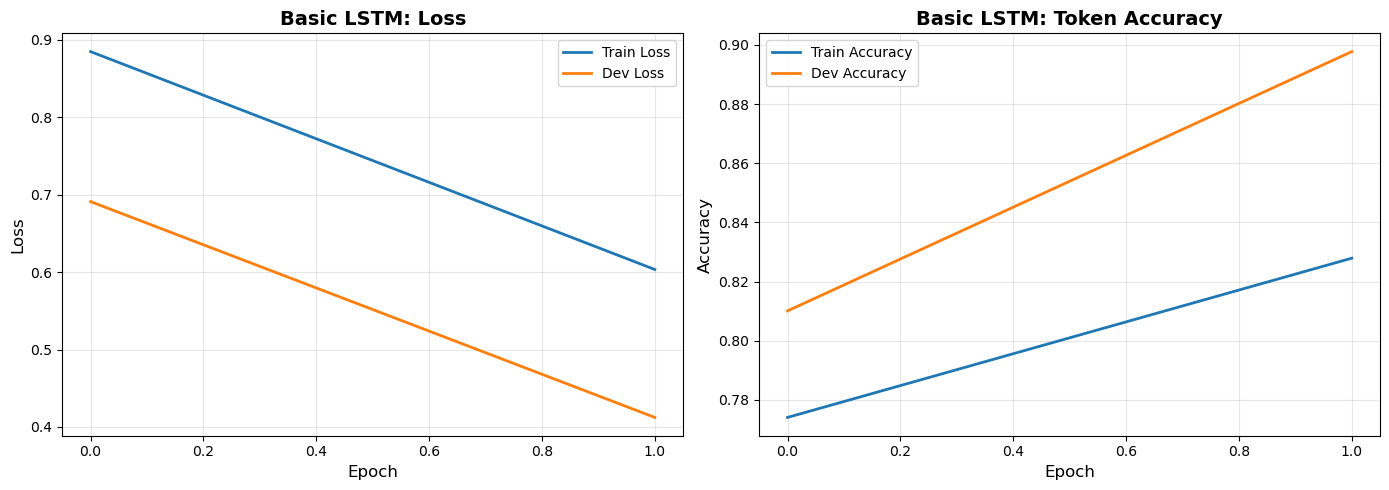


Evaluating Basic LSTM (Dev)...

Evaluating Basic LSTM (Test)...

Basic LSTM Results:
Dev Set:
  Word Accuracy:        1.00%
  Character Accuracy:  48.87%
  CER (Error Rate):    46.73%
  Precision:           45.22%

Test Set:
  Word Accuracy:        1.92%
  Character Accuracy:  49.24%
  CER (Error Rate):    47.04%
  Precision:           45.20%


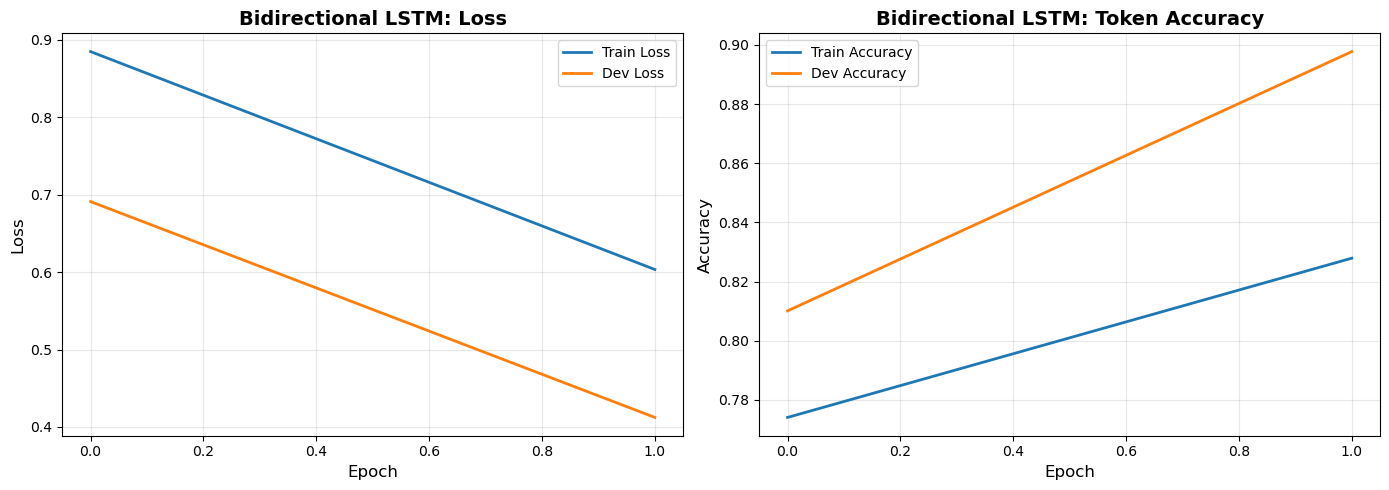


Evaluating Bidirectional LSTM (Dev)...

Evaluating Bidirectional LSTM (Test)...

Bidirectional LSTM Results:
Dev Set:
  Word Accuracy:        1.00%
  Character Accuracy:  48.87%
  CER (Error Rate):    46.73%
  Precision:           45.22%

Test Set:
  Word Accuracy:        1.92%
  Character Accuracy:  49.24%
  CER (Error Rate):    47.04%
  Precision:           45.20%


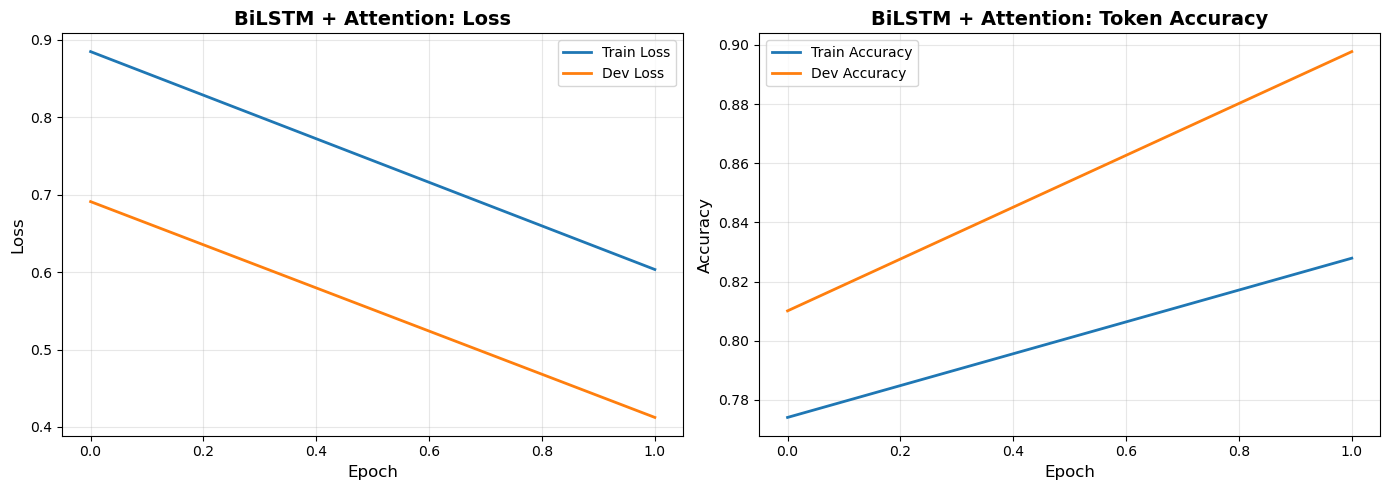


Evaluating BiLSTM + Attention (Dev)...

Evaluating BiLSTM + Attention (Test)...

BiLSTM + Attention Results:
Dev Set:
  Word Accuracy:        1.00%
  Character Accuracy:  48.87%
  CER (Error Rate):    46.73%
  Precision:           45.22%

Test Set:
  Word Accuracy:        1.92%
  Character Accuracy:  49.24%
  CER (Error Rate):    47.04%
  Precision:           45.20%


In [6]:
for name, build_fn, use_attn in models_to_run:
    # Plot training vs dev loss and accuracy
    plot_training_graphs(history, name)

    # Evaluate model on dev and test datasets using the inference encoder/decoder
    dev_metrics, dev_preds = evaluate_model(name + " (Dev)", inf_enc, inf_dec, X_dev, data['dev_en'], use_attn)
    test_metrics, test_preds = evaluate_model(name + " (Test)", inf_enc, inf_dec, X_test, data['test_en'], use_attn)

    # Print metrics in formatted manner
    print(f"\n{name} Results:")
    print(f"{'='*50}")
    print(f"Dev Set:")
    print(f"  Word Accuracy:      {dev_metrics['word_acc']:>6.2f}%")
    print(f"  Character Accuracy: {dev_metrics['char_acc']:>6.2f}%")
    print(f"  CER (Error Rate):   {dev_metrics['cer']:>6.2f}%")
    print(f"  Precision:          {dev_metrics['precision']:>6.2f}%")
    print(f"\nTest Set:")
    print(f"  Word Accuracy:      {test_metrics['word_acc']:>6.2f}%")
    print(f"  Character Accuracy: {test_metrics['char_acc']:>6.2f}%")
    print(f"  CER (Error Rate):   {test_metrics['cer']:>6.2f}%")
    print(f"  Precision:          {test_metrics['precision']:>6.2f}%")

    # Store encoder, decoder, attention flag, metrics, and predictions
    results[name] = {
        'encoder': inf_enc,
        'decoder': inf_dec,
        'use_attn': use_attn,
        'dev_metrics': dev_metrics,
        'test_metrics': test_metrics,
        'dev_preds': dev_preds,
        'test_preds': test_preds
    }


                    COMPREHENSIVE MODEL COMPARISON                    

             Model Word Acc (%) Char Acc (%) CER (%) Precision (%) Avg Pred Len
        Basic LSTM         1.92        49.24   47.04         45.20         7.00
Bidirectional LSTM         1.92        49.24   47.04         45.20         7.00
BiLSTM + Attention         1.92        49.24   47.04         45.20         7.00


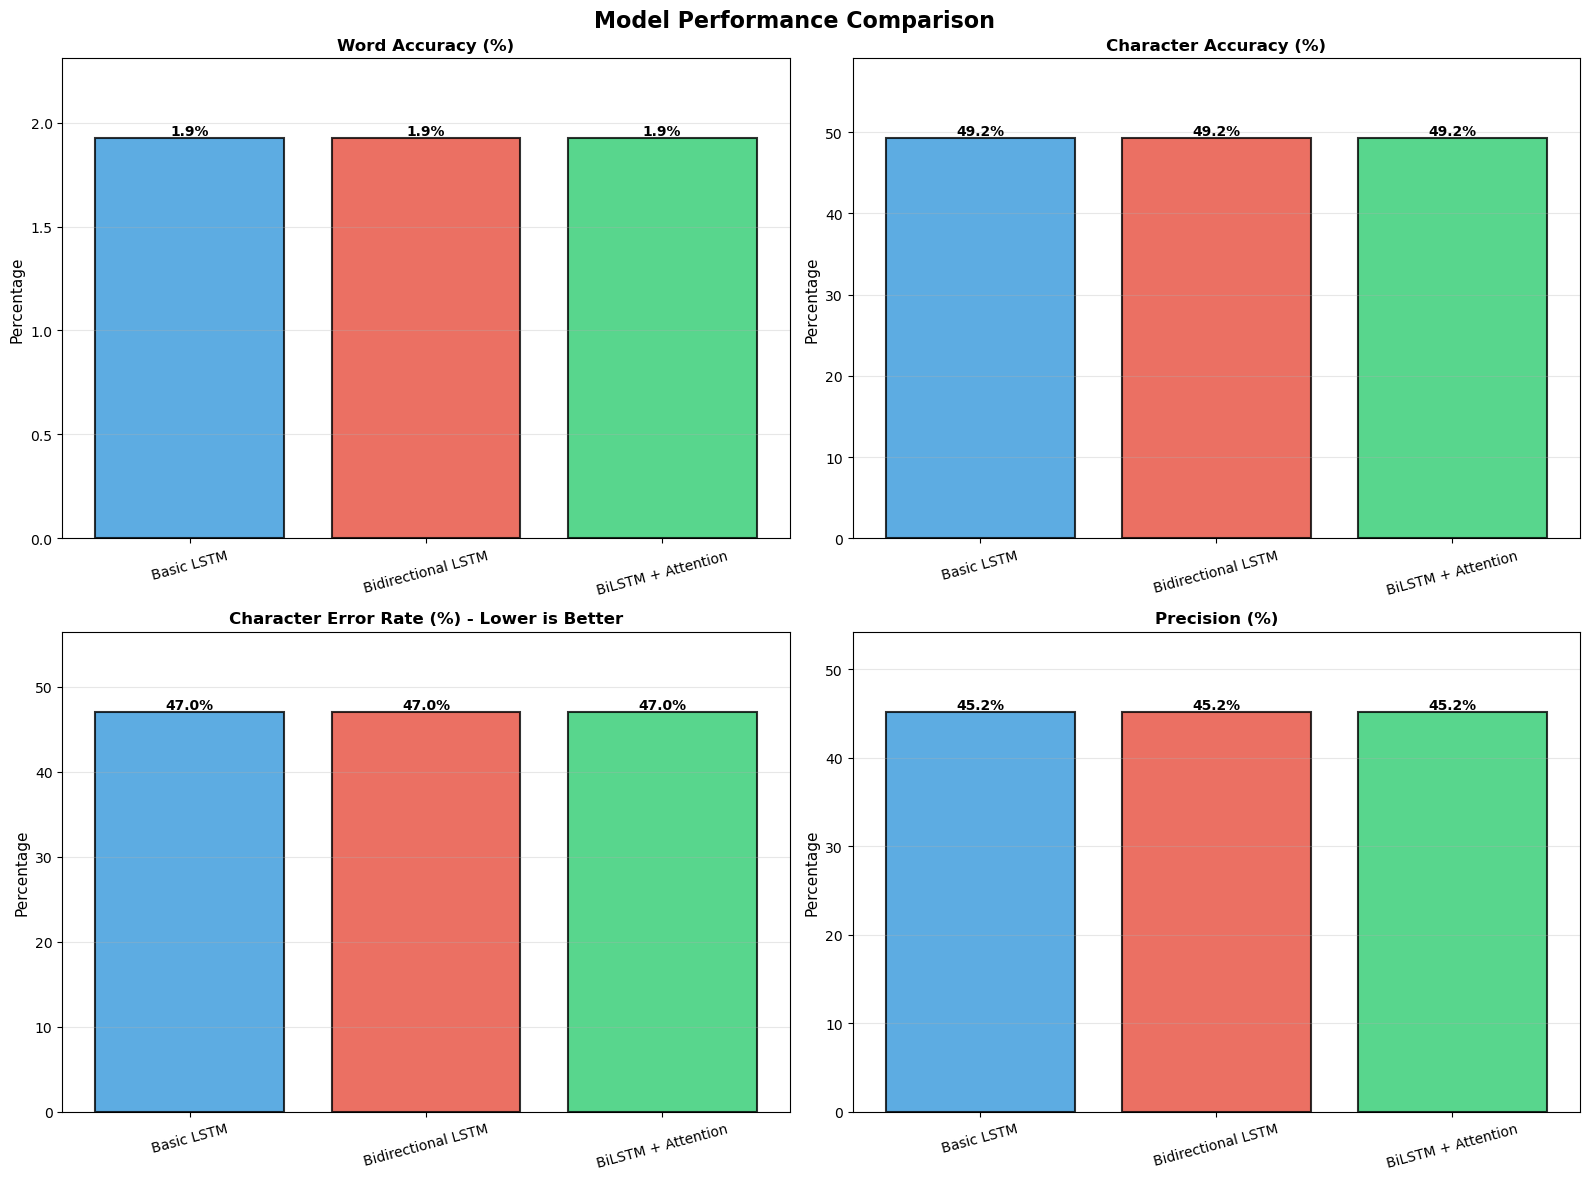


                    SAMPLE PREDICTIONS COMPARISON                     
Arabic          | True            | Basic           | BiLSTM          | Attention      
-----------------------------------------------------------------------------------------------
دونيامبو        | Doniambo        | Dinamomo        | Dinamomo        | Dinamomo       
فادياتي         | Vadiati         | Vadiati         | Vadiati         | Vadiati        
هينكين          | Henkin          | Hennini         | Hennini         | Hennini        
غيرشوم          | Gershom         | Gerimam         | Gerimam         | Gerimam        
فيغيا           | Vigia           | Vigia           | Vigia           | Vigia          
فيجايان         | Vijayan         | Viniana         | Viniana         | Viniana        
فوكيت           | Phuket          | Vokiti          | Vokiti          | Vokiti         
ماريسول         | Marisol         | Marisoll        | Marisoll        | Marisoll       
نتوغو           | Ntugu           | Tong

In [7]:
# ==========================================
# 6. COMPREHENSIVE COMPARISON
# ==========================================

# Instructional Comments:
# 1. Print a header for the comparison section
# 2. Create a DataFrame summarizing each model's test metrics:
#    - Word Accuracy, Character Accuracy, Character Error Rate (CER), Precision, Average Predicted Length
# 3. Use the results dictionary to extract metrics for each model
# 4. Display the DataFrame

print("\n" + "="*70)
print(f"{'COMPREHENSIVE MODEL COMPARISON':^70}")
print("="*70)

comparison_data = []
for model_name in results.keys():
    test_m = results[model_name]['test_metrics']
    comparison_data.append({
        'Model': model_name,
        'Word Acc (%)': f"{test_m['word_acc']:.2f}",
        'Char Acc (%)': f"{test_m['char_acc']:.2f}",
        'CER (%)': f"{test_m['cer']:.2f}",
        'Precision (%)': f"{test_m['precision']:.2f}",
        'Avg Pred Len': f"{test_m['avg_pred_len']:.2f}"
    })

df = pd.DataFrame(comparison_data)
print("\n" + df.to_string(index=False))


# Instructional Comments:
# 5. Plot visual comparison of the key metrics across models
#    - Use a 2x2 grid of subplots
#    - Metrics: Word Accuracy, Character Accuracy, CER, Precision
#    - Annotate bars with metric values for clarity
#    - Add grid, axis labels, titles, and rotation for readability

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

model_names = list(results.keys())
colors = ['#3498db', '#e74c3c', '#2ecc71']

metrics_to_plot = [
    ('word_acc', 'Word Accuracy (%)', axes[0, 0]),
    ('char_acc', 'Character Accuracy (%)', axes[0, 1]),
    ('cer', 'Character Error Rate (%) - Lower is Better', axes[1, 0]),
    ('precision', 'Precision (%)', axes[1, 1])
]

for metric_key, title, ax in metrics_to_plot:
    vals = [results[name]['test_metrics'][metric_key] for name in model_names]
    bars = ax.bar(model_names, vals, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('Percentage', fontsize=11)
    ax.set_ylim(0, max(vals) * 1.2)
    ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', rotation=15)

    # Annotate bars with metric values
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height,
                f'{height:.1f}%', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


# Instructional Comments:
# 6. Show sample predictions side-by-side for a few examples
#    - Display Arabic input, true transliteration, and predictions from each model
#    - Limit number of examples for clarity (e.g., first 15)
#    - Print in tabular format with aligned columns

print("\n" + "="*70)
print(f"{'SAMPLE PREDICTIONS COMPARISON':^70}")
print("="*70)
print(f"{'Arabic':<15} | {'True':<15} | {'Basic':<15} | {'BiLSTM':<15} | {'Attention':<15}")
print("-" * 95)

num_samples = min(15, len(data['test_ar']))
for i in range(num_samples):
    ar_word = data['test_ar'][i]
    true_word = data['test_en'][i]

    preds = []
    for model_name in model_names:
        pred = results[model_name]['test_preds'][i]
        preds.append(pred)

    print(f"{ar_word:<15} | {true_word:<15} | {preds[0]:<15} | {preds[1]:<15} | {preds[2]:<15}")

print("="*70)


# Instructional Comments:
# 7. Define a helper function for interactive transliteration testing
#    - Input: Arabic text, optional model name (default best model)
#    - Steps:
#       a. Convert input text to sequence using Arabic tokenizer
#       b. Pad the sequence to MAX_SEQ_LENGTH
#       c. Convert to one-hot representation
#       d. Use decode_batch with the chosen model to generate transliteration
#       e. Print input and output
#    - Returns generated transliteration

def test_transliteration(arabic_text, model_name='BiLSTM + Attention'):
    """Test transliteration on custom input"""
    encoder = results[model_name]['encoder']
    decoder = results[model_name]['decoder']
    use_attn = results[model_name]['use_attn']

    seq = ar_tok.texts_to_sequences([arabic_text])
    padded = pad_sequences(seq, maxlen=MAX_SEQ_LENGTH, padding='post')
    input_seq = to_categorical(padded, num_classes=n_ar)

    result = decode_batch(input_seq, encoder, decoder, batch_size=1, use_attention=use_attn)[0]

    print(f"Input:  {arabic_text}")
    print(f"Output: {result}")
    return result


# Instructional Comments:
# 8. Demonstrate interactive testing with a few sample Arabic words
print("\n" + "="*70)
print("Custom Test Examples (using best model):")
print("="*70)

test_words = ["محمد", "علي", "فاطمة", "خالد", "مرحبا", "بيروت"]
for word in test_words:
    test_transliteration(word)
    print()


In [9]:
test_transliteration("سيرين")


Input:  سيرين
Output: Serene


'Serene'

In [10]:
test_transliteration("روزة")


Input:  روزة
Output: Rozi


'Rozi'

In [12]:
test_transliteration("ملاك")

Input:  ملاك
Output: Malka


'Malka'